In [1]:
import dask.distributed
import folium
import folium.plugins
import geopandas as gpd
import shapely.geometry
from IPython.display import display
from pystac_client import Client
import matplotlib.pyplot as plt

In [2]:
from odc.stac import configure_rio, stac_load

def convert_bounds(bbox, invert_y=False):
    x1, y1, x2, y2 = bbox
    if invert_y:
        y1, y2 = y2, y1
    return ((y1, x1), (y2, x2))

km2deg = 1.0 / 111
x, y = (113.887, -25.843) # x=경도, y=위도
r = 100 * km2deg
bbox = (x-r, y-r, x+r, y+r)

In [3]:
catalog = Client.open("https://earth-search.aws.element84.com/v1/")
query = catalog.search(
    collections=["sentinel-2-l2a"], datetime="2021-09-16", limit=100, bbox=bbox
)

items = list(query.items())
print(f'Found {len(items):d} datasets\n')

Found 18 datasets



In [4]:
stac_json = query.item_collection_as_dict()
stac_json

{'type': 'FeatureCollection',
 'features': [{'type': 'Feature',
   'stac_version': '1.0.0',
   'id': 'S2A_49JFL_20210916_1_L2A',
   'properties': {'created': '2023-07-11T20:28:26.669Z',
    'platform': 'sentinel-2a',
    'constellation': 'sentinel-2',
    'instruments': ['msi'],
    'eo:cloud_cover': 38.721323,
    'proj:epsg': 32749,
    'mgrs:utm_zone': 49,
    'mgrs:latitude_band': 'J',
    'mgrs:grid_square': 'FL',
    'grid:code': 'MGRS-49JFL',
    'view:sun_azimuth': 46.2397789838852,
    'view:sun_elevation': 50.5685508790514,
    's2:degraded_msi_data_percentage': 0.0514,
    's2:nodata_pixel_percentage': 78.154075,
    's2:saturated_defective_pixel_percentage': 0,
    's2:dark_features_percentage': 0,
    's2:cloud_shadow_percentage': 0,
    's2:vegetation_percentage': 0.00038,
    's2:not_vegetated_percentage': 3e-05,
    's2:water_percentage': 61.278266,
    's2:unclassified_percentage': 0,
    's2:medium_proba_clouds_percentage': 12.401416,
    's2:high_proba_clouds_percent

In [5]:
gdf = gpd.GeoDataFrame.from_features(stac_json, "epsg:4326")

gdf["granule"] = (
    gdf["mgrs:utm_zone"].apply(lambda x: f"{x:02d}")
    + gdf["mgrs:latitude_band"]
    + gdf["mgrs:grid_square"]
)

gdf

,geometry,created,platform,constellation,instruments,eo:cloud_cover,proj:epsg,mgrs:utm_zone,mgrs:latitude_band,mgrs:grid_square,...,s2:granule_id,s2:reflectance_conversion_factor,datetime,s2:sequence,earthsearch:s3_path,earthsearch:payload_id,earthsearch:boa_offset_applied,processing:software,updated,granule
0,"POLYGON ((113.00474 -26.20542, 112.73274 -27.2...",2023-07-11T20:28:26.669Z,sentinel-2a,sentinel-2,[msi],38.721323,32749,49,J,FL,...,S2A_OPER_MSI_L2A_TL_S2RP_20230122T070659_A0325...,0.987871,2021-09-16T02:35:21.194000Z,1,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/F...,roda-sentinel2/workflow-sentinel2-to-stac/f3d5...,True,{'sentinel2-to-stac': '0.1.1'},2023-07-11T20:28:26.669Z,49JFL
1,"POLYGON ((113.00313 -26.20544, 113.09971 -26.2...",2022-11-06T08:34:15.193Z,sentinel-2a,sentinel-2,[msi],35.644225,32749,49,J,FL,...,S2A_OPER_MSI_L2A_TL_VGS1_20210916T064116_A0325...,0.987871,2021-09-16T02:35:21.194000Z,0,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/F...,roda-sentinel2/workflow-sentinel2-to-stac/284e...,False,{'sentinel2-to-stac': '0.1.0'},2022-11-06T08:34:15.193Z,49JFL
2,"POLYGON ((113.0031 -26.20544, 114.09915 -26.18...",2022-11-06T05:19:34.633Z,sentinel-2a,sentinel-2,[msi],23.280485,32749,49,J,GL,...,S2A_OPER_MSI_L2A_TL_VGS1_20210916T064116_A0325...,0.987871,2021-09-16T02:35:16.888000Z,0,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/G...,roda-sentinel2/workflow-sentinel2-to-stac/da35...,False,{'sentinel2-to-stac': '0.1.0'},2022-11-06T05:19:34.633Z,49JGL
3,"POLYGON ((113.0047 -26.20542, 113.01971 -27.19...",2023-07-11T20:28:44.002Z,sentinel-2a,sentinel-2,[msi],27.773514,32749,49,J,GL,...,S2A_OPER_MSI_L2A_TL_S2RP_20230122T070659_A0325...,0.987871,2021-09-16T02:35:16.886000Z,1,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/G...,roda-sentinel2/workflow-sentinel2-to-stac/865b...,True,{'sentinel2-to-stac': '0.1.1'},2023-07-11T20:28:44.002Z,49JGL
4,"POLYGON ((113.99819 -26.18806, 113.97212 -27.1...",2023-07-11T20:28:45.108Z,sentinel-2a,sentinel-2,[msi],45.990753,32750,50,J,KR,...,S2A_OPER_MSI_L2A_TL_S2RP_20230122T070659_A0325...,0.987871,2021-09-16T02:35:13.792000Z,1,s3://sentinel-cogs/sentinel-s2-l2a-cogs/50/J/K...,roda-sentinel2/workflow-sentinel2-to-stac/ead6...,True,{'sentinel2-to-stac': '0.1.1'},2023-07-11T20:28:45.108Z,50JKR
5,"POLYGON ((113.99819 -26.18806, 115.09614 -26.2...",2022-11-06T04:54:13.878Z,sentinel-2a,sentinel-2,[msi],36.032066,32750,50,J,KR,...,S2A_OPER_MSI_L2A_TL_VGS1_20210916T064116_A0325...,0.987871,2021-09-16T02:35:13.792000Z,0,s3://sentinel-cogs/sentinel-s2-l2a-cogs/50/J/K...,roda-sentinel2/workflow-sentinel2-to-stac/344f...,False,{'sentinel2-to-stac': '0.1.0'},2022-11-06T04:54:13.878Z,50JKR
6,"POLYGON ((113.24933 -25.29904, 113.00148 -26.2...",2023-07-11T20:27:52.547Z,sentinel-2a,sentinel-2,[msi],10.003407,32749,49,J,GM,...,S2A_OPER_MSI_L2A_TL_S2RP_20230122T070659_A0325...,0.987871,2021-09-16T02:35:02.585000Z,1,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/G...,roda-sentinel2/workflow-sentinel2-to-stac/7455...,True,{'sentinel2-to-stac': '0.1.1'},2023-07-11T20:27:52.547Z,49JGM
7,"POLYGON ((113.24774 -25.29906, 114.07583 -25.2...",2022-11-06T05:36:41.968Z,sentinel-2a,sentinel-2,[msi],9.179415,32749,49,J,GM,...,S2A_OPER_MSI_L2A_TL_VGS1_20210916T064116_A0325...,0.987871,2021-09-16T02:35:02.585000Z,0,s3://sentinel-cogs/sentinel-s2-l2a-cogs/49/J/G...,roda-sentinel2/workflow-sentinel2-to-stac/5dfd...,False,{'sentinel2-to-stac': '0.1.0'},2022-11-06T05:36:41.968Z,49JGM
8,"POLYGON ((114.02078 -25.2861, 115.11048 -25.30...",2022-11-06T04:57:07.005Z,sentinel-2a,sentinel-2,[msi],26.441591,32750,50,J,KS,...,S2A_OPER_MSI_L2A_TL_VGS1_20210916T064116_A0325...,0.987871,2021-09-16T02:34:59.088000Z,0,s3://sentinel-cogs/sentinel-s2-l2a-cogs/50/J/K...,roda-sentinel2/workflow-sentinel2-to-stac/193c...,False,{'sentinel2-to-stac': '0.1.0'},2022-11-06T04:57:07.005Z,50JKS
9,"POLYGON ((114.02078 -25.2861, 113.99592 -26.27...",2023-07-11T20:29:09.568Z,sentinel-2a,sentinel-2,[msi],36.431858,32750,50,J,KS,...,S2A_OPER_MSI_L2A_TL_S2

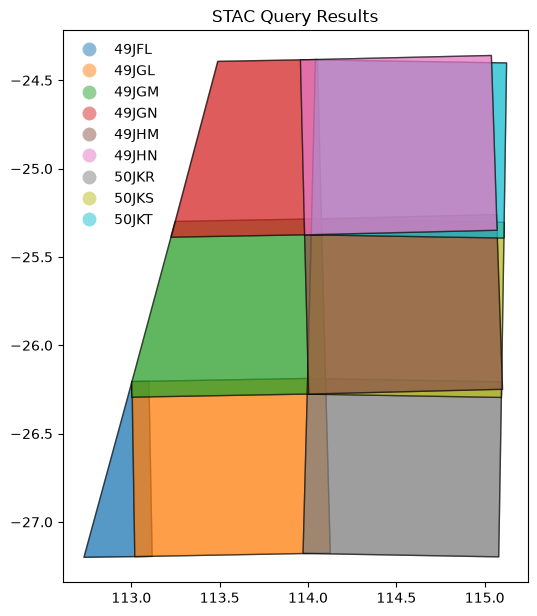

In [6]:
fig = gdf.plot(
    "granule",       # 시각화할 칼럼명
    # kind="geo",    # 차트 모양 (default:geo)
    edgecolor="black",
    categorical=True,
    aspect="equal",
    alpha=0.5,       # 투명도
    figsize=(6, 12), # 차트 사이즈
    legend=True,
    legend_kwds={"loc": "upper left", "frameon": False, "ncol": 1}, # 범례
)
_ = fig.set_title("STAC Query Results")

In [7]:
from branca.element import Figure

fig = Figure(width="600px", height="500px")
map1 = folium.Map()
fig.add_child(map1)

In [8]:
layer = folium.GeoJson(
    shapely.geometry.box(*bbox),
    style_function=lambda x: dict(fill=False, weight=1, opacity=0.7, color="olive"),
    name="Query",
).add_to(map1)

gdf.explore(
    "granule",
    categorical=True,
    tooltip=[
        "granule",
        "datetime",
        "eo:cloud_cover",
    ],
    popup=True,
    style_kwds=dict(fillOpacity=0.1, width=2),
    name="STAC",
    m=map1, # folium.Map
)

In [9]:
map1.fit_bounds(bounds=convert_bounds(gdf.unary_union.bounds))
display(fig)

/tmp/ipykernel_101/4065502932.py:1: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  map1.fit_bounds(bounds=convert_bounds(gdf.unary_union.bounds))


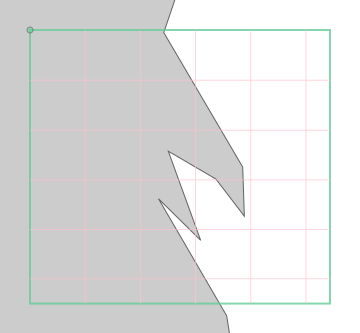

In [10]:
crs = "epsg:3857"
zoom = 2**5  # overview level 5

xx = stac_load(
    items,
    bands=("red", "green", "blue"),
    crs=crs,
    resolution=10 * zoom,
    chunks={},  # <-- use Dask
    groupby="solar_day",
)

xx.odc.geobox